<a href="https://colab.research.google.com/github/uranovnass/Machine-Learning/blob/main/ml6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import re
import string

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [3]:
df = pd.read_csv('/content/IMDB Dataset.csv')

print("Размер датасета:", df.shape)
print("\nПервые 5 строк:")
display(df.head())

print("\nРаспределение классов:")
print(df['sentiment'].value_counts())

print("\nПропущенные значения:")
print(df.isnull().sum())

Размер датасета: (50000, 2)

Первые 5 строк:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive



Распределение классов:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Пропущенные значения:
review       0
sentiment    0
dtype: int64


In [4]:
def clean_text(text):
    text = str(text).lower()                 # нижний регистр
    text = re.sub(r'<[^>]+>', ' ', text)     # удаление HTML-тегов
    text = re.sub(r'[^a-z\s]', ' ', text)    # удаление цифр и пунктуации
    tokens = text.split()                    # токенизация
    tokens = [
        word for word in tokens
        if word not in ENGLISH_STOP_WORDS
    ]                                        # удаление стоп-слов
    return ' '.join(tokens)

df = df.dropna(subset=['review', 'sentiment']).copy()
df['clean_review'] = df['review'].apply(clean_text)

print("Исходный текст:")
print(df['review'].iloc[0][:300])

print("\nОчищенный текст:")
print(df['clean_review'].iloc[0][:300])

Исходный текст:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru

Очищенный текст:
reviewers mentioned watching just oz episode ll hooked right exactly happened thing struck oz brutality unflinching scenes violence set right word trust faint hearted timid pulls punches regards drugs sex violence hardcore classic use word called oz nickname given oswald maximum security state penit


In [5]:
stop_words = set(ENGLISH_STOP_WORDS)
stop_words.discard('not')
stop_words.discard('no')
stop_words.discard('nor')

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r"[^a-z\s']", ' ', text)
    tokens = text.split()
    tokens = [word for word in tokens if word not in stop_words]
    return ' '.join(tokens)

df['clean_review'] = df['review'].apply(clean_text)

print(df[['review', 'clean_review', 'sentiment']].head(3))

                                              review  \
0  One of the other reviewers has mentioned that ...   
1  A wonderful little production. <br /><br />The...   
2  I thought this was a wonderful way to spend ti...   

                                        clean_review sentiment  
0  reviewers mentioned watching just oz episode y...  positive  
1  wonderful little production filming technique ...  positive  
2  thought wonderful way spend time hot summer we...  positive  


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_review'],
    df['sentiment'],
    test_size=0.2,
    random_state=42,
    stratify=df['sentiment']
)

print("Обучающая выборка:", X_train.shape[0])
print("Тестовая выборка:", X_test.shape[0])

Обучающая выборка: 40000
Тестовая выборка: 10000


In [7]:
tfidf = TfidfVectorizer(
    min_df=5,
    max_df=0.9,
    max_features=10000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Размер обучающей матрицы:", X_train_tfidf.shape)
print("Размер тестовой матрицы:", X_test_tfidf.shape)
print("Количество признаков:", len(tfidf.get_feature_names_out()))

Размер обучающей матрицы: (40000, 10000)
Размер тестовой матрицы: (10000, 10000)
Количество признаков: 10000


In [8]:
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nОтчёт классификации:")
print(classification_report(y_test, y_pred))

print("Матрица ошибок:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.8584

Отчёт классификации:
              precision    recall  f1-score   support

    negative       0.86      0.86      0.86      5000
    positive       0.86      0.86      0.86      5000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000

Матрица ошибок:
[[4281  719]
 [ 697 4303]]


In [9]:
errors = pd.DataFrame({
    'text': X_test,
    'true_label': y_test,
    'predicted_label': y_pred
})

errors = errors[
    errors['true_label'] != errors['predicted_label']
]

print("Количество ошибок:", len(errors))

display(errors.sample(
    n=min(5, len(errors)),
    random_state=42
))

Количество ошибок: 1416


,text,true_label,predicted_label
44533,i'm amused disgusted people claim movie accura...,negative,positive
1023,saw sea dust nyc screening audience years ago ...,positive,negative
3955,massive multiple chills spine i'm surprised th...,positive,negative
45465,it's hard believe waiting years wind piece cin...,negative,positive
49750,there's lot going college girl murders mad sci...,positive,negative


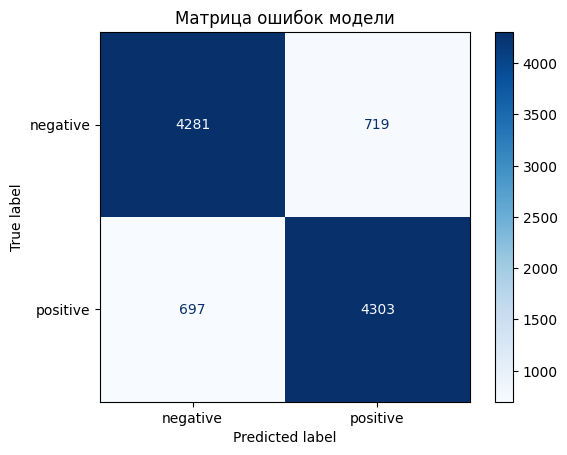

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['negative', 'positive'],
    cmap='Blues'
)

plt.title('Матрица ошибок модели')
plt.show()

In [11]:
import numpy as np

words = np.array(tfidf.get_feature_names_out())
log_probs = model.feature_log_prob_

negative_words = words[np.argsort(
    log_probs[0] - log_probs[1]
)[-15:][::-1]]

positive_words = words[np.argsort(
    log_probs[1] - log_probs[0]
)[-15:][::-1]]

print("Слова, характерные для negative:")
print(negative_words)

print("\nСлова, характерные для positive:")
print(positive_words)

Слова, характерные для negative:
['waste' 'stinker' 'boll' 'worst' 'uwe' 'awful' 'redeeming' 'mst'
 'unwatchable' 'unfunny' 'uninteresting' 'wasting' 'poorly' 'laughable'
 'atrocious']

Слова, характерные для positive:
['ponyo' 'edie' 'matthau' 'felix' 'goldsworthy' 'eisenstein' 'antwone'
 'excellently' 'vance' 'custer' 'gundam' 'wonderfully' 'istanbul'
 'ramones' 'farley']


In [12]:
errors.to_csv(
    '/content/classification_errors.csv',
    index=False
)

print("Таблица ошибок сохранена.")

Таблица ошибок сохранена.


В ходе практической работы был построен пайплайн классификации текстов отзывов о фильмах. Выполнены очистка и нормализация текста, токенизация и удаление стоп-слов с сохранением значимых отрицаний. Для преобразования текстов в числовые признаки использован TF-IDF с ограничением словаря. В качестве классификатора применён Multinomial Naive Bayes. Качество модели оценено с помощью accuracy, precision, recall, F1-score и матрицы ошибок. Дополнительно проанализированы пять неправильно классифицированных отзывов и предложены гипотезы причин ошибок.